# 02 · Train the pix2pix generator (GAN)

Uses the tiles from `01_data.ipynb` (on Google Drive). Runtime: **GPU (T4)**.

1. Sanity check: the model must be able to memorise 20 tiles. If it cannot, there is a bug
   and a full run would waste GPU time.
2. Full training run. Checkpoints go to Drive after every epoch, so if Colab disconnects,
   just re-run this notebook: it resumes from the last epoch.
3. Loss curves.

In [1]:
from google.colab import drive

REPO_URL = "https://github.com/muhammedshahidsds25-collab/kerala-hazard-vision-ai.git"
REPO_DIR = "/content/kerala-hazard-vision-ai"

drive.mount("/content/drive")
!git clone -q {REPO_URL} {REPO_DIR} || git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
# Regular (not editable) install: an editable src-layout install is not importable
# until the runtime restarts.
!pip install -q .

Mounted at /content/drive
/content/kerala-hazard-vision-ai
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import dataclasses
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader

from kerala_hazard_vision_ai.config import load_config
from kerala_hazard_vision_ai.data.dataset import TileDataset, compute_stats
from kerala_hazard_vision_ai.models import build_models
from kerala_hazard_vision_ai.train import fit, make_optimizers, set_seed, train_step

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", force=True)
cfg = load_config("configs/default.yaml")
DRIVE_ROOT = Path("/content/drive/MyDrive") / cfg.data.drive_folder
TILE_DIR = DRIVE_ROOT / "tiles"
CKPT_DIR = DRIVE_ROOT / "checkpoints"
OUT_DIR = DRIVE_ROOT / "outputs" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda Tesla T4


## 1. Overfit sanity check (20 most severe tiles, 200 steps)

L1 first 10 steps: 0.497  last 10: 0.094


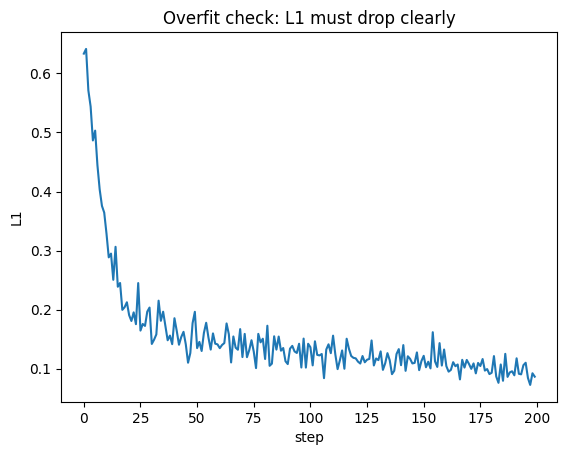

In [3]:
set_seed(cfg.train.seed)
all_tiles = sorted(TILE_DIR.glob("*.npz"))
probe = TileDataset(all_tiles, compute_stats(all_tiles), augment=False)
top20 = [all_tiles[i] for i in probe.severities.argsort()[-20:]]
loader = DataLoader(TileDataset(top20, probe.stats, augment=False), batch_size=4, shuffle=True)

g, d = (m.to(device) for m in build_models(cfg.model))
opt_g, opt_d = make_optimizers(g, d, cfg.train)
l1_curve = []
while len(l1_curve) < 200:
    for x, y in loader:
        losses = train_step(g, d, opt_g, opt_d, x.to(device), y.to(device), cfg.train.l1_weight)
        l1_curve.append(losses["g_l1"])
print(f"L1 first 10 steps: {sum(l1_curve[:10]) / 10:.3f}  last 10: {sum(l1_curve[-10:]) / 10:.3f}")
plt.plot(l1_curve)
plt.xlabel("step")
plt.ylabel("L1")
plt.title("Overfit check: L1 must drop clearly")
del g, d, opt_g, opt_d

## 2. Full training run (resumes automatically)

In [4]:
run_cfg = dataclasses.replace(
    cfg, train=dataclasses.replace(cfg.train, checkpoint_dir=str(CKPT_DIR))
)
best_generator = fit(run_cfg, TILE_DIR, resume=True)
best_generator

2026-11-13 06:47:37,750 Tiles: {'train': 1730, 'val': 278, 'test': 296}
2026-11-13 06:48:30,077 Resumed at epoch 68 (best val_l1 0.0745)
2026-11-13 06:49:46,382 Epoch 68: {'epoch': 68, 'd_loss': 0.6205, 'g_gan': 1.0075, 'g_l1': 0.0868, 'val_l1': 0.0927}
2026-11-13 06:51:28,501 Epoch 69: {'epoch': 69, 'd_loss': 0.6391, 'g_gan': 0.95, 'g_l1': 0.0861, 'val_l1': 0.0795}
2026-11-13 06:53:04,618 Epoch 70: {'epoch': 70, 'd_loss': 0.6383, 'g_gan': 0.9604, 'g_l1': 0.0854, 'val_l1': 0.0801}
2026-11-13 06:54:40,658 Epoch 71: {'epoch': 71, 'd_loss': 0.6347, 'g_gan': 0.9878, 'g_l1': 0.0847, 'val_l1': 0.089}
2026-11-13 06:56:19,226 Epoch 72: {'epoch': 72, 'd_loss': 0.6381, 'g_gan': 0.9416, 'g_l1': 0.0833, 'val_l1': 0.0817}
2026-11-13 06:57:56,222 Epoch 73: {'epoch': 73, 'd_loss': 0.6296, 'g_gan': 0.9414, 'g_l1': 0.0826, 'val_l1': 0.082}
2026-11-13 06:59:34,823 Epoch 74: {'epoch': 74, 'd_loss': 0.6335, 'g_gan': 0.9474, 'g_l1': 0.0841, 'val_l1': 0.0857}
2026-11-13 07:01:10,717 Epoch 75: {'epoch': 75, 

PosixPath('/content/drive/MyDrive/kerala_hazard_vision_ai/checkpoints/best_g.pt')

## 3. Loss curves

,epoch,d_loss,g_gan,g_l1,val_l1
96,95,0.639337,0.930913,0.078700,0.078163
97,96,0.631596,0.914929,0.076988,0.082173
98,97,0.655049,0.937814,0.076206,0.086863
99,98,0.635953,0.936280,0.076080,0.079147
100,99,0.649383,0.901569,0.075636,0.080150


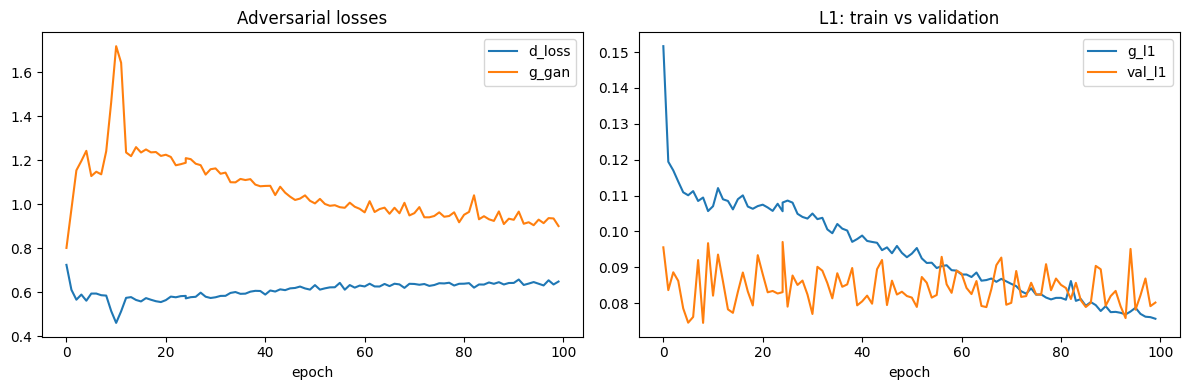

In [5]:
history = pd.read_csv(CKPT_DIR / "history.csv")
fig, (ax_gan, ax_l1) = plt.subplots(1, 2, figsize=(12, 4))
history.plot(x="epoch", y=["d_loss", "g_gan"], ax=ax_gan, title="Adversarial losses")
history.plot(x="epoch", y=["g_l1", "val_l1"], ax=ax_l1, title="L1: train vs validation")
fig.tight_layout()
fig.savefig(OUT_DIR / "losses.png", dpi=150)
history.tail()